In [1]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray
from typing import Tuple

In [2]:
from mcap.reader import make_reader

mcap_file_path_outer = "../data/Maps/outer.mcap"
mcap_file_path_inner_1 = "../data/Maps/inner1.mcap"
mcap_file_path_inner_2 = "../data/Maps/inner2.mcap"


with open(mcap_file_path_outer, "rb") as f:
    reader = make_reader(f)

    # 1. Zusammenfassung der Datei laden
    summary = reader.get_summary()

    if summary:
        print("--- ALLGEMEINE STATISTIKEN ---")
        stats = summary.statistics
        print(f"Nachrichten insgesamt: {stats.message_count}")
        print(f"Anzahl Kanäle/Topics: {stats.channel_count}")
        print(f"Startzeit (Nanosekunden): {stats.message_start_time}")
        print(f"Endzeit (Nanosekunden): {stats.message_end_time}")

        print("\n--- REGISTRIERTE SCHEMATA (Datentypen) ---")
        for schema_id, schema in summary.schemas.items():
            print(f"ID {schema_id}: {schema.name} (Typ: {schema.encoding})")

        print("\n--- AKTIVE KANÄLE (Topics) ---")
        for channel_id, channel in summary.channels.items():
            # Zugehöriges Schema finden
            schema_name = summary.schemas[channel.schema_id].name if channel.schema_id in summary.schemas else "Kein Schema"
            print(f"Topic: '{channel.topic}' | Typ: {schema_name} | Encoding: {channel.message_encoding}")
    else:
        print("Die Datei enthält keine Summary-Sektion. Sie muss sequenziell gescannt werden.")


--- ALLGEMEINE STATISTIKEN ---
Nachrichten insgesamt: 20654
Anzahl Kanäle/Topics: 2
Startzeit (Nanosekunden): 1760100720466395132
Endzeit (Nanosekunden): 1760100761770344943

--- REGISTRIERTE SCHEMATA (Datentypen) ---
ID 1: tf2_msgs/msg/TFMessage (Typ: ros2msg)
ID 2: nav_msgs/msg/Odometry (Typ: ros2msg)

--- AKTIVE KANÄLE (Topics) ---
Topic: '/tf' | Typ: tf2_msgs/msg/TFMessage | Encoding: cdr
Topic: '/mapping_tool/odometry' | Typ: nav_msgs/msg/Odometry | Encoding: cdr


In [3]:
from mcap_ros2.decoder import DecoderFactory

def decode_msg(path: str, get_data: bool) -> Tuple[NDArray, NDArray] | Tuple[None, None]:
    x = []
    y = []

    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])

        for i, (schema, channel, message, msg) in enumerate(
            reader.iter_decoded_messages(topics=["/mapping_tool/odometry"])
        ):
            position = msg.pose.pose.position
            orientation = msg.pose.pose.orientation

            if get_data:
                x.append(position.x)
                y.append(position.y)
            else:
                print(f"\nMessage {i}")
                print(f"Reference frame: {msg.header.frame_id}")
                print(f"Tracked frame:   {msg.child_frame_id}")
                print(f"Stamp: {msg.header.stamp.sec} s + "
                      f"{msg.header.stamp.nanosec} ns")
                print(f"Position: x={position.x}, y={position.y}, z={position.z}")
                print(f"Orientation: x={orientation.x}, y={orientation.y}, "
                      f"z={orientation.z}, w={orientation.w}")

                if i >= 5:
                    break

    if get_data:
        return np.array(x), np.array(y)
    else:
        return None, None

decode_msg(mcap_file_path_outer, False)


Message 0
Reference frame: map
Tracked frame:   mapping_tool
Stamp: 1760100720 s + 465906381 ns
Position: x=5.059316551904079, y=1.3268272487936903, z=0.08821270138543513
Orientation: x=-0.16142994109611974, y=0.18071925762450788, z=-0.6381023476232041, w=-0.7306191234216537

Message 1
Reference frame: map
Tracked frame:   mapping_tool
Stamp: 1760100720 s + 469913244 ns
Position: x=5.059267490659031, y=1.3270119336776356, z=0.08818160209009013
Orientation: x=-0.1614467771157722, y=0.1807628366523565, z=-0.6379791932227425, w=-0.730712166019906

Message 2
Reference frame: map
Tracked frame:   mapping_tool
Stamp: 1760100720 s + 473875522 ns
Position: x=5.059213087974381, y=1.327079304935023, z=0.08821466269022626
Orientation: x=-0.161457367351092, y=0.18082365464427644, z=-0.6378195677229123, w=-0.7308341186543084

Message 3
Reference frame: map
Tracked frame:   mapping_tool
Stamp: 1760100720 s + 477876663 ns
Position: x=5.059206019430512, y=1.327207555721846, z=0.08824640939531841
Orie

(None, None)

In [4]:
x_outer, y_outer = decode_msg(mcap_file_path_outer, True)

x_inner_1, y_inner_1 = decode_msg(mcap_file_path_inner_1, True)

x_inner_2, y_inner_2 = decode_msg(mcap_file_path_inner_2, True)

Text(0, 0.5, 'y')

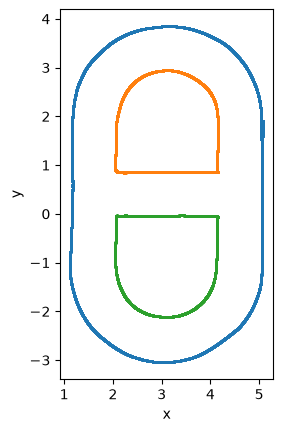

In [5]:
plt.scatter(x_outer, y_outer, s=1)
plt.scatter(x_inner_1, y_inner_1, s=1)
plt.scatter(x_inner_2, y_inner_2, s=1)

plt.gca().set_aspect("equal", adjustable="box")

plt.xlabel("x")
plt.ylabel("y")

# plt.xlim(-4, 6)
# plt.ylim(-4, 6)

In [6]:
# Loop over the path segments and average n consecutive points (close in time measurements) to obtain fewer
# points that are still a sequence and that have smaller positional errors (CLT)

print(len(x_outer))

def point_averages(x_array: NDArray, y_array: NDArray, n: int) -> Tuple[NDArray, NDArray]:
    x_averages = []
    y_averages = []

    max_index = int(len(x_array) / n)

    for i in range(max_index):
        x_average = np.mean(x_array[i * n: (i + 1) * n])
        y_average = np.mean(y_array[i * n: (i + 1) * n])

        x_averages.append(x_average)
        y_averages.append(y_average)

    return np.array(x_averages), np.array(y_averages)

10327


In [7]:
n_avg = 50
x_outer_avg, y_outer_avg = point_averages(x_outer, y_outer, n_avg)
x_inner_1_avg, y_inner_1_avg = point_averages(x_inner_1, y_inner_1, n_avg)
x_inner_2_avg, y_inner_2_avg = point_averages(x_inner_2, y_inner_2, n_avg)

Text(0, 0.5, 'y')

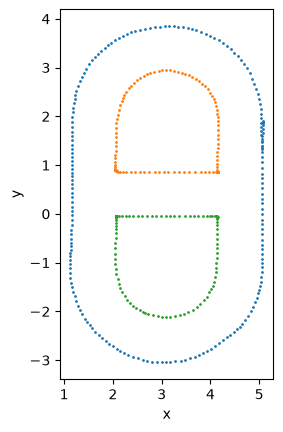

In [8]:
plt.scatter(x_outer_avg, y_outer_avg, s=1)
plt.scatter(x_inner_1_avg, y_inner_1_avg, s=1)
plt.scatter(x_inner_2_avg, y_inner_2_avg, s=1)

plt.gca().set_aspect("equal", adjustable="box")

# plt.ylim(3, 5)

plt.xlabel("x")
plt.ylabel("y")

In [9]:
# Adjust x so all values are positive to avoid 'wrappings' in the grid map. Probably just need to invert
# the transformation at the end. Apply it to all to ensure consistency.
y_outer += 3.5
y_inner_1 += 3.5
y_inner_2 += 3.5

In [10]:
# Try to rasterize the map such that we have a boolean map of 'line' / 'no line'. This way,
# we can then easier create the points to plot by getting rid duplicates and similars.
# First however count occurrences.

y_range = [0, 7.5]
x_range = [0.5, 6]

resolution = 0.1

x_dim = int(round(x_range[1] - x_range[0]) / resolution)
y_dim = int(round(y_range[1] - y_range[0]) / resolution)

grid_map = np.zeros((x_dim, y_dim))

print(np.shape(grid_map))

(60, 80)


In [11]:
# Now we essentially want to loop over the points and increment the grid point where the value lies
# For this a small helper function might be useful.

# Example: x = 1.35, resolution = 0.1. Then x / resolution = 13.5 and since x < resolution should be at index 0,
# this means that x_index = int(x / resolution), i.e. rounding down / truncating.

def get_grid_position(x: float, y: float) -> Tuple[int, int]:
    # The -1 kind of makes no sense but just trying it out.
    x_index = int(x / resolution) - 1
    y_index = int(y / resolution) - 1

    return x_index, y_index

# Then now we want a function that loops over the array and updates the entries accordingly
def update_grid_map(x_array: NDArray, y_array: NDArray) -> None:
    for x, y in zip(x_array, y_array):
        x_index, y_index = get_grid_position(x, y)
        grid_map[x_index, y_index] += 1

    return None

In [12]:
update_grid_map(x_outer, y_outer)

In [13]:
print(grid_map)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


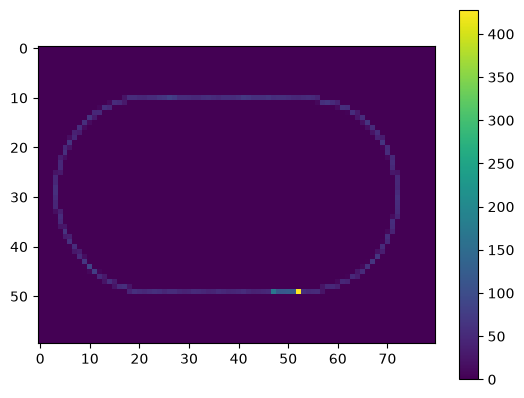

In [14]:
plt.imshow(grid_map, cmap="viridis")
plt.colorbar()
# plt.axis("off")  # Drop this line if you need row/column indices to locate anomalies

# plt.gca().set_aspect("equal", adjustable="box")

plt.show()

In [15]:
# Now we want to extract the new points from the grid map again. For this we use the center (can later be
# improved by shifted overlays / averaging).

# Actually, it seems like it is not that easy to extract a sequence of points. Only again a set (but unordered).
# However, with a specified starting point and some proximity heuristics, this might just work... The initial
# attempt will only return a set for now.
def extract_from_map(map_array: NDArray, bound: int = 1) -> NDArray:
    """Extract entries larger than zero (or the specified min bound (inclusive)) from the grid map and turn
    them back to 2d points. Returns an array of x,y coordinates."""

    shape = np.shape(map_array)
    point_set = []

    for i in range(shape[0]):
        for j in range(shape[1]):
            if map_array[i, j] >= bound:
                x = resolution / 2 + i * resolution
                y = resolution / 2 + j * resolution
                point_set.append((x, y))

    return np.array(point_set)

In [16]:
points = extract_from_map(grid_map)

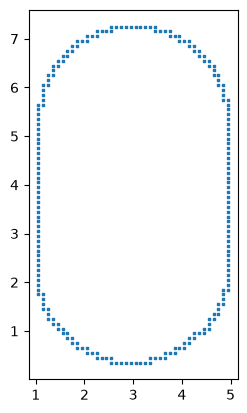

In [17]:
plt.scatter(points[:, 0], points[:, 1], s=1, marker='s')
plt.gca().set_aspect("equal", adjustable="box")

In [18]:
# Then to maybe average everything a bit, we could create the same map with small shifts in x and y try to build
# a more accurate representation from this.